### **Student Information**
GitHub ID:YJC714

Kaggle name:YUN-JUNG CHANG

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

* **Loading the data:** I merged final_posts.json with data_identification.csv (train/test split) and
  emotion.csv (labels), which gave 3360 training posts and 1440 test posts with 6 types of emotions (anger, fear, sadness, joy, disgust, surprise).
* **Class distribution:** The classes are not balanced: joy is the largest class (875) and fear is the smallest. (288) This matters because the metric is macro F1, whose score reflects the average of each type pf label. Therefore, I used class_weight="balanced" for the baseline, and for RoBERTa I tuned per-class weights on the OOF predictions, so the model pays equal attention to each label.
* **Text cleaning:** I only did light cleaning:
    * replaced URLs with URL and user mentions with USER, because they have nothing to do with emotion labeling.
    * shortened letters repeated 4+ times (e.g. "soooooo"→"sooo"), because they are deviated from real words. If there's too many deviations, it causes extremely large vocabulary size and difficulties for the model to learn.
    * kept punctuation and casing, because they also express emotions. For example, exclamation mark is emphasis of emotion, and this helps the model recognize the emotion.
* For the RoBERTa model I used the raw text, because it was trained on raw internet text, which means it understood the meaning of emojis, punctuations, upper/lower cases.


### 1.2 Feature Engineering Steps

* **TF-IDF (baseline):** I combined two TF-IDF vectorizers:
    * word 1-2 grams, to capture words more accurately.  Negation could cause the opposite meaning of the adjectives. (e.g. "not bad", "not fair")
    * character 2-5 grams, to handle extended words (e.g. happyyy, noooooooo)
* **RoBERTa:** the text is split into sub-word tokens by the pretrained tokenizer (max 128 tokens), and the features are learned by the model itself during fine-tuning, instead of hand-designed features like TF-IDF word counts.


### 1.3 Explanation of Your Model

* **Baseline:** TF-IDF + Linear SVM with class_weight="balanced". I tried C = 0.1 , 0.3, 1.0 with
  5-fold cross-validation; the best CV macro F1 was about 0.517. It passes the 0.5 baseline but only barely.
* **Main model:** I fine-tuned j-hartmann/emotion-english-roberta-large. I chose it because it is a emotion model, using anger, disgust, neutral, fear, joy, sadness, and surprise labels, nearly the same as our model.
  I replaced its output layer with a six-class layer.
* **Training:** five-fold cross-validation, 4 epochs, learning rate 1.5e-5, batch size 16. In each
  fold I kept the epoch with the best validation macro F1, and averaged the test probabilities of the
  five folds.
* **Improvements I tried:**
| Attempt | OOF macro F1 | Public score | Result |
| --- | --- | --- | --- |
| One seed (42) | 0.6266 | 0.6167 | first submission |
| + per-class weights | not recorded | 0.6167 | - |
| 2 seeds averaged | 0.6385 | 0.6164 | - |
| 3 seeds averaged (final) | 0.6409 | 0.6295 | the best score | 
### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

| My Question | AI suggestion | My Decision | 
| --- | --- | --- | 
| My score is 0.6167 and someone got 0.67, how can I improve? | (1) tune per-class weights on OOF (2) average several seeds | I tried both. The per-class weights did not change the public score, so I focused on averaging seeds, which raised the public score from 0.6167 to 0.6295. |
| Which trained model can we use? |  fine-tune j-hartmann/emotion-english-roberta-large on a Kaggle GPU | I checked the labels used in the roberta first and used it


* The competition code in this notebook was written by AI based on my requests. I ran it on Kaggle, and also asked AI to help fix errors. I used each edited version only after making sure I understood what it did.
---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [19]:
### 1.1 Load the competition data
# Put the four Kaggle files (final_posts.json, data_identification.csv, emotion.csv,
# sampleSubmission.csv) in data/kaggle/ of this repository, or attach the competition
# as input when running on Kaggle. The cell searches both places.
import glob, json, os, re
import numpy as np
import pandas as pd

def find_data_dir():
    for d in ["data/kaggle", "kaggle data"]:
        if os.path.isfile(os.path.join(d, "final_posts.json")):
            return d
    for root, _, files in os.walk("/kaggle/input", followlinks=True):   # Kaggle mounts inputs here
        if "final_posts.json" in files:
            return root
    listing = [os.path.join(r, f) for r, _, fs in os.walk("/kaggle/input", followlinks=True) for f in fs][:30]
    raise FileNotFoundError(
        "final_posts.json not found. On Kaggle: '+ Add Input' -> Competitions -> "
        "2026-dm-lab-2-private-competition. Locally: put the files in data/kaggle/. "
        f"Files currently under /kaggle/input: {listing}")

DATA_DIR = find_data_dir()
print("Data folder:", DATA_DIR)

posts = pd.DataFrame(json.load(open(os.path.join(DATA_DIR, "final_posts.json"), encoding="utf-8")))
split = pd.read_csv(os.path.join(DATA_DIR, "data_identification.csv"))   # post_id -> train / test
labels = pd.read_csv(os.path.join(DATA_DIR, "emotion.csv"))              # post_id -> label (train only)
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sampleSubmission.csv"))

df = posts.merge(split, on="post_id")
train_df = df[df["set"] == "train"].merge(labels, on="post_id").reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)
print(f"train: {len(train_df)}  test: {len(test_df)}")

Data folder: /kaggle/input/competitions/2026-dm-lab-2-private-competition
train: 3360  test: 1440


label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


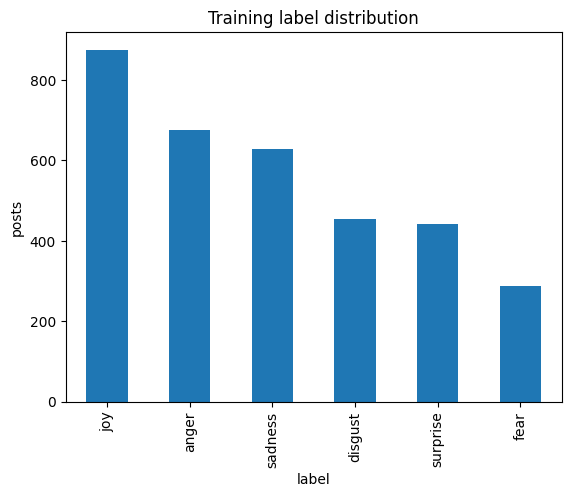

Text length (words):
count    3360.000000
mean       16.508333
std        24.958839
min         1.000000
25%         8.000000
50%        13.000000
75%        19.000000
max       508.000000
Name: text, dtype: float64


In [20]:
### 1.2 Look at the label distribution (the classes are imbalanced)
import matplotlib.pyplot as plt

counts = train_df["label"].value_counts()
print(counts)
counts.plot(kind="bar", title="Training label distribution")
plt.ylabel("posts")
plt.show()

print("Text length (words):")
print(train_df["text"].str.split().str.len().describe())

In [21]:
### 1.3 Light text cleaning
# Keep punctuation, casing cues and emoji-like tokens because they carry emotion ("!!", "?!").
# Only normalise things that add noise: curly quotes, URLs, user mentions, repeated whitespace.
def clean_text(text: str) -> str:
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"(.)\1{3,}", r"\1\1\1", text)     # "soooooo" -> "sooo"
    return re.sub(r"\s+", " ", text).strip()

train_df["clean"] = train_df["text"].map(clean_text)
test_df["clean"] = test_df["text"].map(clean_text)

LABELS = sorted(train_df["label"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
y = train_df["label"].map(label2id).values
print(LABELS)
train_df[["text", "clean", "label"]].head()

['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


,text,clean,label
0,Thought it looked weird as well.,Thought it looked weird as well.,disgust
1,Bear died in a pit,Bear died in a pit,disgust
2,I have endured worse.,I have endured worse.,sadness
3,The pottery around Brasov is in danger,The pottery around Brasov is in danger,fear
4,"Meanwhile, our soldiers were approaching the a...","Meanwhile, our soldiers were approaching the a...",fear


## 2. Feature Engineering Steps

In [22]:
### 2.1 TF-IDF features (baseline)
# Word 1-2 grams capture emotion words and short phrases ("so happy", "not fair");
# character 2-5 grams are robust to typos, slang and word variants.
from sklearn.pipeline import make_union
from sklearn.feature_extraction.text import TfidfVectorizer

def make_tfidf():
    return make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, lowercase=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
    )

X_demo = make_tfidf().fit_transform(train_df["clean"])
print("TF-IDF matrix:", X_demo.shape)

TF-IDF matrix: (3360, 92345)


In [23]:
### 2.2 Transformer features
# For the stronger model the features are learned: the text is split into sub-word tokens by the
# pretrained tokenizer, and the fine-tuned transformer produces the representation (Section 3.2).
MODEL_NAME = "j-hartmann/emotion-english-roberta-large"   # smaller option: "j-hartmann/emotion-english-distilroberta-base"
MAX_LEN = 128

## 3. Model Implementation Steps

In [24]:
### 3.1 Baseline: TF-IDF + Linear SVM (CPU, about 1 minute)
# class_weight="balanced" compensates for the rare classes (fear, surprise) so macro-F1 is not
# dominated by joy. 5-fold stratified CV estimates the leaderboard score before submitting.
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for C in [0.1, 0.3, 1.0]:
    pipe = make_pipeline(make_tfidf(), LinearSVC(C=C, class_weight="balanced"))
    results[C] = cross_val_score(pipe, train_df["clean"], y, cv=cv, scoring="f1_macro").mean()
    print(f"C={C}: CV macro-F1 = {results[C]:.4f}")

best_C = max(results, key=results.get)
baseline = make_pipeline(make_tfidf(), LinearSVC(C=best_C, class_weight="balanced"))
baseline.fit(train_df["clean"], y)

def write_submission(pred_ids, path):
    pred = dict(zip(test_df["post_id"], [LABELS[i] for i in pred_ids]))
    sub = sample_sub[["post_id"]].copy()
    sub["label"] = sub["post_id"].map(pred)
    assert sub["label"].notna().all()
    sub = sub.rename(columns={"post_id": "id"})   # Kaggle 評分要求的欄名是 id
    sub.to_csv(path, index=False)
    print("saved", path, sub["label"].value_counts().to_dict())

write_submission(baseline.predict(test_df["clean"]), "submission_tfidf.csv")

C=0.1: CV macro-F1 = 0.5166
C=0.3: CV macro-F1 = 0.5134
C=1.0: CV macro-F1 = 0.5097
saved submission_tfidf.csv {'joy': 415, 'anger': 315, 'sadness': 268, 'surprise': 183, 'disgust': 147, 'fear': 112}


In [25]:
### 3.2 Fine-tuned RoBERTa (needs a GPU: Kaggle / Colab, about 1 hour for 5 folds)
# The checkpoint was already trained for emotion classification with almost the same labels
# (anger, disgust, fear, joy, sadness, surprise + neutral), so we replace its head with a 6-class head
# and fine-tune it on our posts. 5-fold training: each fold keeps its best epoch by validation
# macro-F1, and the five models' test probabilities are averaged.
import torch
from sklearn.metrics import f1_score

if not torch.cuda.is_available():
    print("No GPU found - skipping 3.2. Run this notebook on Kaggle/Colab with a GPU for this model.")
else:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    BATCH, EPOCHS, LR, FOLDS, SEED = 16, 4, 1.5e-5, 5, 2026
    device = "cuda"
    torch.manual_seed(SEED); np.random.seed(SEED)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    enc = lambda texts: tok(list(texts), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    enc_tr, enc_te = enc(train_df["text"]), enc(test_df["text"])   # raw text: the tokenizer handles casing/punctuation

    def batches(e, idx, labels=None, shuffle=False):
        idx = np.random.permutation(idx) if shuffle else idx
        for s in range(0, len(idx), BATCH):
            b = idx[s:s + BATCH]
            out = {k: v[b].to(device) for k, v in e.items()}
            if labels is not None:
                out["labels"] = torch.tensor(labels[b]).to(device)
            yield out

    def predict_proba(m, e):
        m.eval(); outs = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for b in batches(e, np.arange(len(e["input_ids"]))):
                outs.append(torch.softmax(m(**b).logits.float(), -1).cpu().numpy())
        return np.concatenate(outs)

    oof = np.zeros((len(train_df), len(LABELS)))
    test_prob = np.zeros((len(test_df), len(LABELS)))
    for fold, (tr_i, va_i) in enumerate(StratifiedKFold(FOLDS, shuffle=True, random_state=SEED).split(train_df, y)):
        m = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=label2id,
            ignore_mismatched_sizes=True).to(device)
        opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.01)
        steps = EPOCHS * ((len(tr_i) + BATCH - 1) // BATCH)
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.amp.GradScaler("cuda")
        best = (-1, None, None)
        for ep in range(EPOCHS):
            m.train()
            for b in batches(enc_tr, tr_i, y, shuffle=True):
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = m(**b).loss
                opt.zero_grad(); scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
            va = predict_proba(m, {k: v[va_i] for k, v in enc_tr.items()})
            f1 = f1_score(y[va_i], va.argmax(1), average="macro")
            print(f"fold {fold} epoch {ep}: val macro-F1 = {f1:.4f}")
            if f1 > best[0]:
                best = (f1, va, predict_proba(m, enc_te))
        oof[va_i] = best[1]
        test_prob += best[2] / FOLDS
        del m, opt; torch.cuda.empty_cache()

    print("Out-of-fold macro-F1:", round(f1_score(y, oof.argmax(1), average="macro"), 4))
    np.save("test_prob_roberta.npy", test_prob)
    write_submission(test_prob.argmax(1), "submission.csv")

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-roberta-large
Key                        | Status   |                                                                                         
---------------------------+----------+-----------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 1024]) vs model:torch.Size([6, 1024])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


fold 0 epoch 0: val macro-F1 = 0.6214
fold 0 epoch 1: val macro-F1 = 0.6331
fold 0 epoch 2: val macro-F1 = 0.6422
fold 0 epoch 3: val macro-F1 = 0.6318


[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

... (11 outputs left out)

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-roberta-large
Key                        | Status   |                                                                                         
---------------------------+----------+-----------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 1024]) vs model:torch.Size([6, 1024])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


fold 4 epoch 0: val macro-F1 = 0.6465
fold 4 epoch 1: val macro-F1 = 0.6788
fold 4 epoch 2: val macro-F1 = 0.6571
fold 4 epoch 3: val macro-F1 = 0.6649
Out-of-fold macro-F1: 0.6337
saved submission.csv {'joy': 398, 'anger': 345, 'sadness': 254, 'surprise': 189, 'disgust': 143, 'fear': 111}


              precision    recall  f1-score   support

       anger      0.597     0.660     0.627       674
     disgust      0.531     0.432     0.476       454
        fear      0.709     0.642     0.674       288
         joy      0.731     0.777     0.753       875
     sadness      0.662     0.661     0.661       628
    surprise      0.621     0.601     0.611       441

    accuracy                          0.651      3360
   macro avg      0.642     0.629     0.634      3360
weighted avg      0.648     0.651     0.648      3360



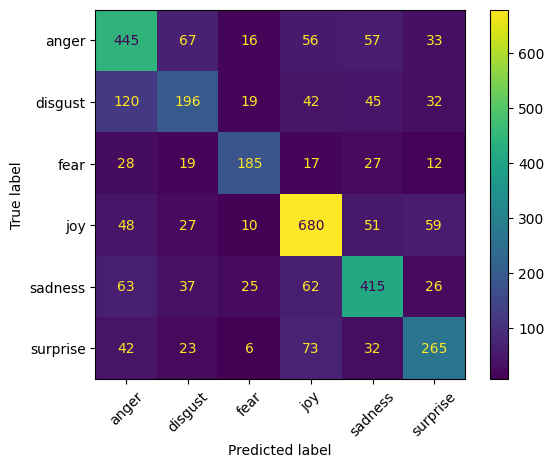

In [26]:
### 3.3 Error analysis on the out-of-fold predictions (run after 3.2)
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

if "oof" in globals():
    print(classification_report(y, oof.argmax(1), target_names=LABELS, digits=3))
    ConfusionMatrixDisplay.from_predictions(y, oof.argmax(1), display_labels=LABELS, xticks_rotation=45)
    plt.show()

In [27]:
### 3.4 Tune per-class weights on out-of-fold predictions to maximise macro-F1
def tune_class_weights(P, y_true, rounds=3):
    w = np.ones(P.shape[1])
    for _ in range(rounds):
        for c in range(len(w)):
            best_f1, best_g = -1, w[c]
            for g in np.linspace(0.5, 2.5, 41):
                w_try = w.copy(); w_try[c] = g
                f = f1_score(y_true, (P * w_try).argmax(1), average="macro")
                if f > best_f1:
                    best_f1, best_g = f, g
            w[c] = best_g
    return w

print("OOF macro-F1 before:", round(f1_score(y, oof.argmax(1), average="macro"), 4))
class_w = tune_class_weights(oof, y)
print("weights:", dict(zip(LABELS, class_w.round(2))))
print("OOF macro-F1 after :", round(f1_score(y, (oof * class_w).argmax(1), average="macro"), 4))
write_submission((test_prob * class_w).argmax(1), "submission_weighted.csv")

OOF macro-F1 before: 0.6337
weights: {'anger': np.float64(0.95), 'disgust': np.float64(1.0), 'fear': np.float64(1.0), 'joy': np.float64(0.55), 'sadness': np.float64(0.8), 'surprise': np.float64(1.2)}
OOF macro-F1 after : 0.638
saved submission_weighted.csv {'anger': 356, 'joy': 343, 'sadness': 243, 'surprise': 226, 'disgust': 155, 'fear': 117}


In [28]:
### 3.5 Save the current model's predictions so several runs can be averaged
runs = globals().get("runs", [])
runs.append((oof.copy(), test_prob.copy()))
print(len(runs), "run(s) saved")

4 run(s) saved


In [39]:
### 3.6 Ensemble: average the saved runs, re-tune class weights, write the final submission
oof = np.mean([r[0] for r in runs], axis=0)
test_prob = np.mean([r[1] for r in runs], axis=0)
print("Ensemble OOF macro-F1 (no weights):", round(f1_score(y, oof.argmax(1), average="macro"), 4))
class_w = tune_class_weights(oof, y)
print("Ensemble OOF macro-F1 (weighted):  ", round(f1_score(y, (oof * class_w).argmax(1), average="macro"), 4))
write_submission((test_prob * class_w).argmax(1), "submission_ensemble.csv")

Ensemble OOF macro-F1 (no weights): 0.6334
Ensemble OOF macro-F1 (weighted):   0.6409
saved submission_ensemble.csv {'joy': 370, 'anger': 290, 'sadness': 263, 'disgust': 212, 'surprise': 210, 'fear': 95}


In [30]:
for i, (o, t) in enumerate(runs):
    print(i, "OOF macro-F1 =", round(f1_score(y, o.argmax(1), average="macro"), 4),
          "| same as previous:", i > 0 and np.allclose(o, runs[i-1][0]))

0 OOF macro-F1 = 0.6266 | same as previous: False
1 OOF macro-F1 = 0.629 | same as previous: False
2 OOF macro-F1 = 0.6337 | same as previous: False
3 OOF macro-F1 = 0.6337 | same as previous: True
